# ChefBot - Entrega 2: Redes neuronales convolucionales (CNN)

**Equipo:** Alvaro, Adan, Angel, Vencha

**IMPORTANTE antes de ejecutar:** activa la GPU en Colab: *Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU*.
Sin GPU, el entrenamiento tardaría horas.

**Cómo usarlo:**
1. Sube el notebook a Colab, activa la GPU y ejecuta las celdas **en orden** (Entorno de ejecución > Ejecutar todo).
2. Si todavía tienes abierta la sesión de Colab de la Entrega 1, el dataset ya está descargado y esta parte será rápida.
   Si no, se vuelve a descargar (~10 min). La división 70/15/15 queda **idéntica** a la de la Entrega 1 (misma semilla).
3. En la sección 6 hay que **escribir a mano** los resultados del mejor modelo clásico de la Entrega 1.
4. Tiempo total aproximado con GPU T4: entre 25 y 45 minutos.

| Sección | Responsable sugerido | Qué hace |
|---|---|---|
| 1. Datos | Alvaro | Recarga el dataset y la misma división de la Entrega 1 |
| 2. CNN propia | Adan | Arquitectura, aumento de datos, callbacks y curvas |
| 3. Variaciones | Adan | Experimentos con profundidad y tasa de aprendizaje |
| 4. Transfer learning | Angel | MobileNetV2 preentrenado |
| 5. Curva de aprendizaje | Angel | Entrenar con 25 %, 50 % y 100 % de los datos |
| 6. Comparación y errores | Vencha | CNN vs mejor modelo clásico y análisis de errores |
| 7. Guardar modelo | Alvaro | Modelo final para la Entrega 3 |

In [ ]:
# ============================================================
# 0. CONFIGURACIÓN GENERAL (ejecutar siempre primero)
# ============================================================
import os, random, time, json, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

# Semilla fija (misma que en la Entrega 1)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

CLASES = ["pizza", "hamburger", "sushi", "caesar_salad", "tacos",
          "ice_cream", "spaghetti_bolognese", "omelette",
          "chocolate_cake", "hot_and_sour_soup"]

IMG_SIZE = 128
BATCH = 64
EPOCAS_CNN = 40      # máximo de épocas para la CNN propia (el early stopping puede parar antes)
EPOCAS_TL = 15       # máximo de épocas de transfer learning (fase 1: solo la cabeza)
EPOCAS_FT = 10       # máximo de épocas de ajuste fino (fase 2)

DATA_DIR = Path("/content/data")
IMG_DIR = DATA_DIR / "food-101" / "images"
sns.set_theme(style="whitegrid")

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponible:", gpus)
if not gpus:
    print("\n*** ADVERTENCIA: no hay GPU. Ve a Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU ***")

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# 1. Datos  *(Responsable: Alvaro)*

Se repite la carga y la división de la Entrega 1 para trabajar exactamente con **los mismos conjuntos** de entrenamiento,
validación y prueba. Así la comparación entre la CNN y el mejor modelo clásico es justa.

In [2]:
# Descargar Food-101 solo si no está ya en esta sesión de Colab
if not IMG_DIR.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    archivo = "/content/food-101.tar.gz"
    url = "https://data.vision.ee.ethz.ch/cvl/food-101.tar.gz"

    print("Descargando Food-101 (~5 GB). Puede tardar varios minutos...")
    subprocess.run(["wget", "-q", "-c", url, "-O", archivo], check=True)

    print("Extrayendo solo las 10 clases...")
    rutas = [f"food-101/images/{c}" for c in CLASES]
    subprocess.run(["tar", "-xzf", archivo, "-C", str(DATA_DIR)] + rutas, check=True)
    os.remove(archivo)
    print("Listo.")
else:
    print("El dataset ya estaba descargado en esta sesión.")

Descargando Food-101 (~5 GB). Puede tardar varios minutos...
Extrayendo solo las 10 clases...
Listo.


In [3]:
# Lista de imágenes (mismo orden que en la Entrega 1: rutas ordenadas)
registros = []
for c in CLASES:
    for p in sorted((IMG_DIR / c).glob("*.jpg")):
        registros.append((str(p), c))
df = pd.DataFrame(registros, columns=["ruta", "clase"])

# Cargar y redimensionar a 128x128 (valores 0-255, tipo uint8)
imagenes, clases_ok, danadas = [], [], []
for ruta, clase in tqdm(zip(df.ruta, df.clase), total=len(df)):
    try:
        with Image.open(ruta) as im:
            im = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            imagenes.append(np.asarray(im, dtype=np.uint8))
            clases_ok.append(clase)
    except Exception:
        danadas.append(ruta)

X_img = np.stack(imagenes)
y_nombres = np.array(clases_ok)
print("Imágenes cargadas:", X_img.shape[0], "| dañadas:", len(danadas))

  0%|          | 0/10000 [00:00<?, ?it/s]

Imágenes cargadas: 10000 | dañadas: 0


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

le = LabelEncoder()
y = le.fit_transform(y_nombres)
nombres_clases = list(le.classes_)
N_CLASES = len(nombres_clases)

# MISMA división 70/15/15 estratificada con semilla 42 que en la Entrega 1
idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=SEED)

X_tr_img, y_train = X_img[idx_train], y[idx_train]
X_val_img, y_val = X_img[idx_val], y[idx_val]
X_test_img, y_test = X_img[idx_test], y[idx_test]

print(f"Entrenamiento: {len(idx_train)} | Validación: {len(idx_val)} | Prueba: {len(idx_test)}")

# Si todavía existe el archivo de la Entrega 1 (misma sesión), verificar que la división es idéntica
if os.path.exists("/content/features.npz"):
    ent1 = np.load("/content/features.npz")
    print("¿División idéntica a la Entrega 1?",
          np.array_equal(ent1["idx_test"], idx_test) and np.array_equal(ent1["idx_train"], idx_train))
else:
    print("(No se encontró features.npz de la Entrega 1; la división se reconstruye con la misma semilla.)")

## 1.1 Funciones auxiliares (pipeline de datos, evaluación y gráficas)

In [5]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

AUTOTUNE = tf.data.AUTOTUNE

def hacer_ds(X, y_etq, entrenamiento=False):
    # Convierte arreglos de numpy en un pipeline de tf.data (con mezcla aleatoria en entrenamiento)
    ds = tf.data.Dataset.from_tensor_slices((X, y_etq))
    if entrenamiento:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

def evaluar(modelo, X, y_real):
    # Devuelve las mismas métricas de la Entrega 1 (promedio macro) y las predicciones
    prob = modelo.predict(hacer_ds(X, y_real), verbose=0)
    pred = prob.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_real, pred, average="macro")
    return {"accuracy": accuracy_score(y_real, pred), "precision": p, "recall": r, "f1": f1}, pred

def graficar_curvas(hist, titulo, linea_vertical=None):
    # Curvas de pérdida y precisión (entrenamiento vs validación) para diagnosticar sobreajuste
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist["loss"], label="entrenamiento")
    ax[0].plot(hist["val_loss"], label="validación")
    ax[0].set_title("Pérdida")
    ax[1].plot(hist["accuracy"], label="entrenamiento")
    ax[1].plot(hist["val_accuracy"], label="validación")
    ax[1].set_title("Precisión (accuracy)")
    for a in ax:
        a.set_xlabel("Época")
        a.legend()
        if linea_vertical is not None:
            a.axvline(linea_vertical, color="gray", linestyle="--")
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

def callbacks():
    # Early stopping: detiene si la pérdida de validación no mejora en 8 épocas y recupera los mejores pesos
    # ReduceLROnPlateau: reduce a la mitad la tasa de aprendizaje si se estanca 3 épocas
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                              min_lr=1e-7, verbose=1)]

def compilar(modelo, optimizador="adam", lr=1e-3):
    if optimizador == "adam":
        opt = keras.optimizers.Adam(learning_rate=lr)
    else:
        opt = keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    modelo.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def entrenar(modelo, X_tr, y_tr, X_va, y_va, epocas, verbose=2):
    t0 = time.time()
    h = modelo.fit(hacer_ds(X_tr, y_tr, entrenamiento=True),
                   validation_data=hacer_ds(X_va, y_va),
                   epochs=epocas, callbacks=callbacks(), verbose=verbose)
    return h.history, time.time() - t0

print("Funciones auxiliares listas.")

Funciones auxiliares listas.


---
# 2. CNN propia  *(Responsable: Adan)*

## 2.1 Arquitectura y justificación de cada decisión

| Decisión | Por qué |
|---|---|
| **Bloques de 2 convoluciones 3x3** (32 → 64 → 128 filtros) | Dos filtros 3x3 seguidos "ven" una zona de 5x5 con menos parámetros que un solo filtro 5x5. Duplicar los filtros en cada bloque permite aprender primero bordes y colores simples, y después formas más complejas. |
| **Batch Normalization** después de cada convolución | Estabiliza y acelera el entrenamiento, y permite usar tasas de aprendizaje más altas. También regulariza un poco. |
| **ReLU** | Activación simple que evita el problema del gradiente que desaparece. |
| **MaxPooling 2x2** al final de cada bloque | Reduce el tamaño de la imagen a la mitad, baja el costo de cómputo y da algo de tolerancia a pequeños desplazamientos. |
| **Dropout 0.25** en los bloques y **0.5** en la capa densa | Apaga neuronas al azar al entrenar para evitar el sobreajuste. Es más fuerte en la capa densa porque ahí hay más parámetros. |
| **GlobalAveragePooling** en vez de Flatten | Reduce muchísimo los parámetros de la capa densa (menos sobreajuste con solo ~7,000 imágenes de entrenamiento). |
| **Capa densa de 128 + softmax de 10** | Combina las características aprendidas y entrega una probabilidad por platillo. |
| **Rescaling 1/255** dentro del modelo | El modelo guardado acepta imágenes 0-255 directamente, lo cual simplifica la Entrega 3. |
| **Aumento de datos** dentro del modelo | Solo se activa al entrenar; al predecir no hace nada. |

In [6]:
def capa_aumento():
    # Aumento de datos: genera variaciones aleatorias de cada foto en cada época
    return keras.Sequential([
        layers.RandomFlip("horizontal"),         # espejo horizontal
        layers.RandomRotation(0.05),             # giro de hasta ~18 grados
        layers.RandomZoom(0.15),                 # acercamiento / alejamiento
        layers.RandomTranslation(0.1, 0.1),      # desplazamiento
        layers.RandomContrast(0.2),              # cambios de contraste
    ], name="aumento_de_datos")

def bloque_conv(x, filtros, dropout):
    # Bloque: Conv-BN-ReLU x2 -> MaxPool -> Dropout
    x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(dropout)(x)
    return x

def construir_cnn(filtros=(32, 64, 128), dropout_conv=0.25, unidades=128,
                  dropout_densa=0.5, aumento=True, nombre="cnn_propia"):
    entradas = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))     # imagen 0-255
    x = entradas
    if aumento:
        x = capa_aumento()(x)
    x = layers.Rescaling(1.0 / 255)(x)                        # normalizar a 0-1
    for f in filtros:
        x = bloque_conv(x, f, dropout_conv)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(unidades, activation="relu")(x)
    x = layers.Dropout(dropout_densa)(x)
    salidas = layers.Dense(N_CLASES, activation="softmax")(x)
    return keras.Model(entradas, salidas, name=nombre)

def entrenar_cnn_config(cfg, X_tr, y_tr, X_va, y_va, verbose=2, nombre="cnn_propia"):
    # Construye, compila y entrena una CNN con la configuración dada
    keras.utils.set_random_seed(SEED)
    m = construir_cnn(filtros=cfg["filtros"], aumento=cfg["aumento"], nombre=nombre)
    compilar(m, cfg.get("optimizador", "adam"), cfg["lr"])
    h, t = entrenar(m, X_tr, y_tr, X_va, y_va, EPOCAS_CNN, verbose=verbose)
    return m, h, t

# Vista previa de la arquitectura base
modelo_demo = construir_cnn()
modelo_demo.summary()

Model: "cnn_propia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_de_datos (Sequential)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

## 2.2 Efecto del aumento de datos
Ejemplo visual: una misma foto transformada varias veces por la capa de aumento.

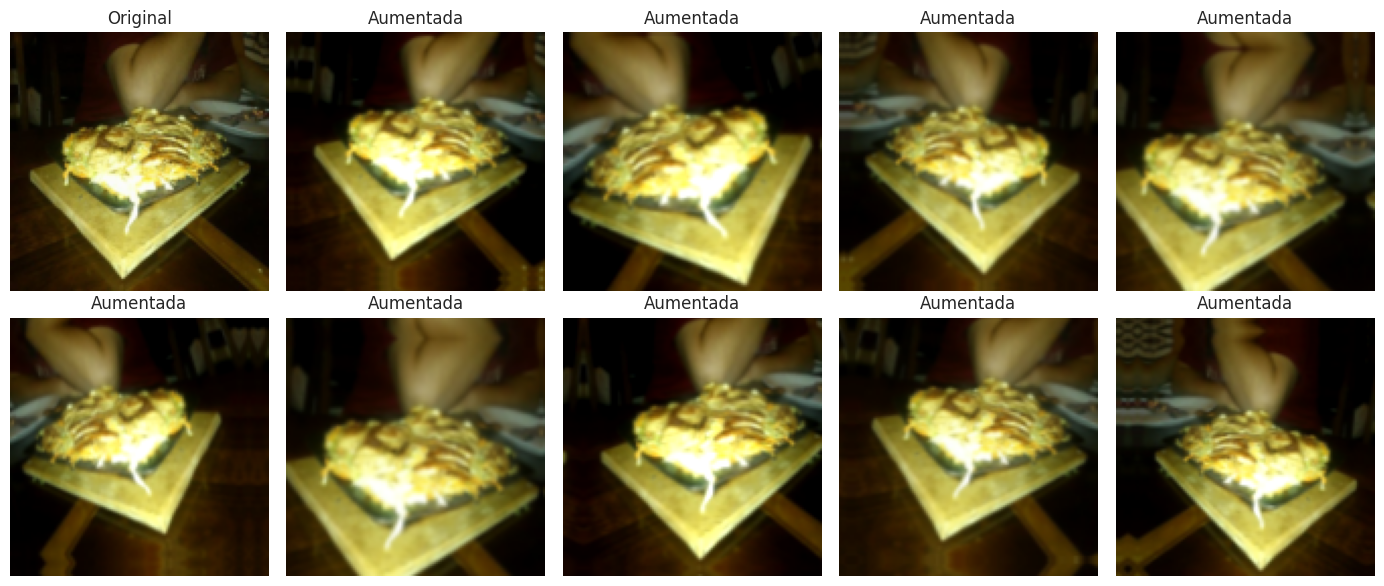

In [7]:
aug = capa_aumento()
foto = X_tr_img[0:1].astype("float32")
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes[0, 0].imshow(X_tr_img[0]); axes[0, 0].set_title("Original")
for ax in axes.ravel()[1:]:
    ax.imshow(aug(foto, training=True)[0].numpy().clip(0, 255).astype("uint8"))
    ax.set_title("Aumentada")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2.3 Entrenamiento del modelo base
Se entrena con **early stopping** y **reducción de la tasa de aprendizaje**. Después se grafican las curvas para ver si hay sobreajuste
(cuando la pérdida de entrenamiento sigue bajando pero la de validación sube o se estanca).

Epoch 1/40
110/110 - 35s - 319ms/step - accuracy: 0.2454 - loss: 2.1291 - val_accuracy: 0.1353 - val_loss: 2.5449 - learning_rate: 0.0010
Epoch 2/40
110/110 - 19s - 174ms/step - accuracy: 0.3183 - loss: 1.9424 - val_accuracy: 0.1767 - val_loss: 2.2392 - learning_rate: 0.0010
Epoch 3/40
110/110 - 20s - 177ms/step - accuracy: 0.3494 - loss: 1.8522 - val_accuracy: 0.2347 - val_loss: 2.1730 - learning_rate: 0.0010
Epoch 4/40
110/110 - 20s - 180ms/step - accuracy: 0.3986 - loss: 1.7447 - val_accuracy: 0.3387 - val_loss: 1.9133 - learning_rate: 0.0010
Epoch 5/40
110/110 - 20s - 183ms/step - accuracy: 0.4311 - loss: 1.6402 - val_accuracy: 0.1307 - val_loss: 3.5332 - learning_rate: 0.0010
Epoch 6/40
110/110 - 20s - 184ms/step - accuracy: 0.4574 - loss: 1.5758 - val_accuracy: 0.2720 - val_loss: 2.5491 - learning_rate: 0.0010
Epoch 7/40
110/110 - 20s - 183ms/step - accuracy: 0.4870 - loss: 1.4844 - val_accuracy: 0.4033 - val_loss: 1.7715 - learning_rate: 0.0010
Epoch 8/40
110/110 - 20s - 185ms/s

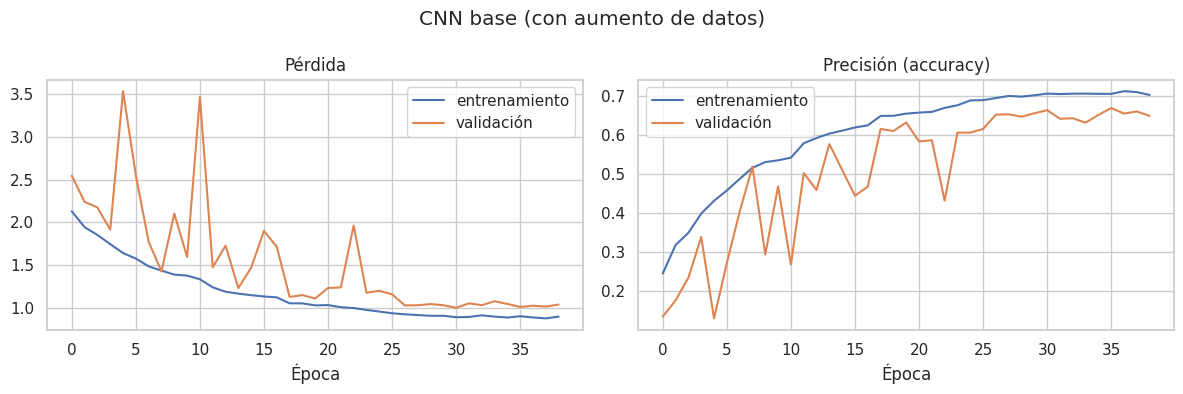

In [8]:
cfg_base = dict(filtros=(32, 64, 128), lr=1e-3, aumento=True)
modelo_base, hist_base, t_base = entrenar_cnn_config(
    cfg_base, X_tr_img, y_train, X_val_img, y_val, nombre="cnn_base")
print(f"\nEntrenamiento terminado en {t_base:.0f} s y {len(hist_base['loss'])} épocas.")
graficar_curvas(hist_base, "CNN base (con aumento de datos)")

**Observaciones para el informe (Adan):** ¿en qué época dejó de mejorar la validación? ¿Hay brecha entre entrenamiento
y validación (sobreajuste)? ¿Se redujo la tasa de aprendizaje en algún momento?

---
# 3. Experimentos y variaciones  *(Responsable: Adan)*

Se compara el modelo base con:
- **Sin aumento de datos** (para medir el efecto del aumento).
- **Variación A:** más profunda (4 bloques, hasta 256 filtros).
- **Variación B:** tasa de aprendizaje más baja (3e-4).

> Esta celda entrena 3 modelos más. Tarda varios minutos.

In [ ]:
experimentos = {
    "Base (3 bloques, Adam 1e-3, con aumento)": cfg_base,
    "Sin aumento de datos": dict(filtros=(32, 64, 128), lr=1e-3, aumento=False),
    "Variación A: más profunda (4 bloques)": dict(filtros=(32, 64, 128, 256), lr=1e-3, aumento=True),
    "Variación B: tasa de aprendizaje 3e-4": dict(filtros=(32, 64, 128), lr=3e-4, aumento=True),
}

resultados_cnn = {}
# El modelo base ya está entrenado: se reutiliza
resultados_cnn["Base (3 bloques, Adam 1e-3, con aumento)"] = dict(
    modelo=modelo_base, hist=hist_base, tiempo=t_base, cfg=cfg_base)

for nombre, cfg in experimentos.items():
    if nombre in resultados_cnn:
        continue
    print(f"\n===== {nombre} =====")
    m, h, t = entrenar_cnn_config(cfg, X_tr_img, y_train, X_val_img, y_val,
                                  verbose=0, nombre="exp")
    resultados_cnn[nombre] = dict(modelo=m, hist=h, tiempo=t, cfg=cfg)
    print(f"   terminado en {t:.0f} s ({len(h['loss'])} épocas)")

In [ ]:
# Tabla comparativa de experimentos (en VALIDACIÓN)
filas = []
for nombre, r in resultados_cnn.items():
    h = r["hist"]
    mejor_ep = int(np.argmin(h["val_loss"]))          # época con mejor pérdida de validación
    met, _ = evaluar(r["modelo"], X_val_img, y_val)
    r["val"] = met
    filas.append({
        "Experimento": nombre,
        "Parámetros": r["modelo"].count_params(),
        "Épocas": len(h["loss"]),
        "Acc. train": h["accuracy"][mejor_ep],
        "Acc. val": met["accuracy"],
        "F1 val": met["f1"],
        "Brecha (train-val)": h["accuracy"][mejor_ep] - h["val_accuracy"][mejor_ep],
        "Tiempo (s)": r["tiempo"],
    })

tabla_exp = pd.DataFrame(filas).set_index("Experimento")
tabla_exp = tabla_exp.round({"Acc. train": 3, "Acc. val": 3, "F1 val": 3, "Brecha (train-val)": 3, "Tiempo (s)": 0})
display(tabla_exp)

mejor_cnn_nombre = tabla_exp["F1 val"].idxmax()
mejor_cnn = resultados_cnn[mejor_cnn_nombre]
print(f"\nMejor CNN propia según F1 en validación: {mejor_cnn_nombre}")

In [ ]:
# Curvas de todos los experimentos
for nombre, r in resultados_cnn.items():
    graficar_curvas(r["hist"], nombre)

**Observaciones para el informe (Adan):**
- *Efecto del aumento de datos:* compara "Base" contra "Sin aumento de datos". Fíjate en la **brecha (train-val)**:
  sin aumento suele ser mayor (más sobreajuste). Nota: la precisión de entrenamiento con aumento y dropout se mide con datos
  deformados, por eso suele verse más baja.
- *Profundidad:* ¿más bloques ayudaron o solo aumentaron el tiempo y el sobreajuste?
- *Tasa de aprendizaje:* ¿una tasa más baja converge mejor o solo más lento?

---
# 4. Transfer learning con MobileNetV2  *(Responsable: Angel)*

**Idea:** en vez de empezar desde cero, se usa MobileNetV2, una red ya entrenada con ~1.4 millones de imágenes (ImageNet),
que ya sabe detectar bordes, texturas y formas. Se hace en 2 fases:

1. **Fase 1:** se congela MobileNetV2 y solo se entrena la capa final (la "cabeza") para los 10 platillos.
2. **Fase 2 (ajuste fino):** se descongelan las últimas 40 capas y se reentrenan con una tasa de aprendizaje muy baja (1e-5).

In [ ]:
def construir_transfer(nombre="mobilenetv2_transfer"):
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                          include_top=False, weights="imagenet")
    base.trainable = False                                    # congelar el modelo preentrenado
    entradas = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = capa_aumento()(entradas)
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)         # MobileNetV2 espera valores entre -1 y 1
    x = base(x, training=False)                               # BatchNorm en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    salidas = layers.Dense(N_CLASES, activation="softmax")(x)
    return keras.Model(entradas, salidas, name=nombre), base

def entrenar_transfer(X_tr, y_tr, X_va, y_va, ult_capas=40, verbose=2):
    keras.utils.set_random_seed(SEED)
    modelo, base = construir_transfer()

    # Fase 1: solo la cabeza
    compilar(modelo, "adam", 1e-3)
    h1, t1 = entrenar(modelo, X_tr, y_tr, X_va, y_va, EPOCAS_TL, verbose=verbose)

    # Fase 2: ajuste fino de las últimas capas con tasa de aprendizaje muy baja
    base.trainable = True
    for capa in base.layers[:-ult_capas]:
        capa.trainable = False
    compilar(modelo, "adam", 1e-5)
    h2, t2 = entrenar(modelo, X_tr, y_tr, X_va, y_va, EPOCAS_FT, verbose=verbose)

    hist = {k: list(h1[k]) + list(h2.get(k, [])) for k in h1}
    return modelo, hist, len(h1["loss"]), t1 + t2

modelo_tl, hist_tl, fin_fase1, t_tl = entrenar_transfer(X_tr_img, y_train, X_val_img, y_val)
print(f"\nTransfer learning terminado en {t_tl:.0f} s.")
graficar_curvas(hist_tl, "MobileNetV2 (línea gris = inicio del ajuste fino)", linea_vertical=fin_fase1)

In [ ]:
# Comparación en VALIDACIÓN: CNN propia vs transfer learning
met_tl_val, _ = evaluar(modelo_tl, X_val_img, y_val)
comp_val = pd.DataFrame({
    f"CNN propia ({mejor_cnn_nombre})": mejor_cnn["val"],
    "MobileNetV2 (transfer learning)": met_tl_val,
}).T.round(3)
display(comp_val)
print("Parámetros CNN propia:", mejor_cnn["modelo"].count_params(),
      "| Parámetros MobileNetV2:", modelo_tl.count_params())

**Observaciones para el informe (Angel):** ¿el transfer learning superó a la CNN propia? ¿Por cuánto?
¿Por qué crees que ayuda tener una red preentrenada con tan pocas imágenes? ¿Cuánto mejoró el ajuste fino respecto a la fase 1?

---
# 5. Curva de aprendizaje: ¿cuántas imágenes hacen falta?  *(Responsable: Angel)*

Se entrena la mejor CNN propia y el modelo de transfer learning con **25 %, 50 % y 100 %** de las imágenes de entrenamiento
(subconjuntos estratificados, con la misma validación y prueba). Los resultados del 100 % se reutilizan de las secciones anteriores.

> Entrena 4 modelos más. Tarda varios minutos.

In [14]:
def subconjunto(frac):
    # Subconjunto estratificado del entrenamiento (mantiene la proporción de clases)
    if frac >= 1.0:
        return idx_train
    sub, _ = train_test_split(idx_train, train_size=frac,
                              stratify=y[idx_train], random_state=SEED)
    return sub

curva = []
for frac in [0.25, 0.5, 1.0]:
    sub = subconjunto(frac)
    print(f"\n--- {int(frac*100)}% de los datos de entrenamiento: {len(sub)} imágenes ---")
    if frac == 1.0:
        m_cnn, m_tl = mejor_cnn["modelo"], modelo_tl
    else:
        m_cnn, _, _ = entrenar_cnn_config(mejor_cnn["cfg"], X_img[sub], y[sub],
                                          X_val_img, y_val, verbose=0, nombre="curva_cnn")
        m_tl, _, _, _ = entrenar_transfer(X_img[sub], y[sub], X_val_img, y_val, verbose=0)

    for nombre, m in [("CNN propia", m_cnn), ("Transfer learning", m_tl)]:
        mv, _ = evaluar(m, X_val_img, y_val)
        mt, _ = evaluar(m, X_test_img, y_test)
        curva.append({"Modelo": nombre, "% de datos": int(frac * 100), "Imágenes": len(sub),
                      "Acc. val": mv["accuracy"], "Acc. prueba": mt["accuracy"], "F1 prueba": mt["f1"]})
        print(f"   {nombre}: acc. validación {mv['accuracy']:.3f} | acc. prueba {mt['accuracy']:.3f}")

tabla_curva = pd.DataFrame(curva)
display(tabla_curva.round(3))


--- 25% de los datos de entrenamiento: 1750 imágenes ---

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.

Epoch 7: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
   CNN propia: acc. validación 0.133 | acc. prueba 0.145
   Transfer learning: acc. validación 0.779 | acc. prueba 0.790

--- 50% de los datos de entrenamiento: 3500 imágenes ---

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 20: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 26: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 32: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 35: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 12: ReduceLROnPlateau reducing learning rate to 0.0005000000

,Modelo,% de datos,Imágenes,Acc. val,Acc. prueba,F1 prueba
0,CNN propia,25,1750,0.133,0.145,0.058
1,Transfer learning,25,1750,0.779,0.790,0.788
2,CNN propia,50,3500,0.625,0.625,0.611
3,Transfer learning,50,3500,0.799,0.792,0.788
4,CNN propia,100,7000,0.753,0.745,0.737
5,Transfer learning,100,7000,0.795,0.799,0.795


In [ ]:
# Gráfica de la curva de aprendizaje
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for nombre in ["CNN propia", "Transfer learning"]:
    d = tabla_curva[tabla_curva["Modelo"] == nombre]
    ax[0].plot(d["Imágenes"], d["Acc. prueba"], marker="o", label=nombre)
    ax[1].plot(d["Imágenes"], d["F1 prueba"], marker="o", label=nombre)
ax[0].set_title("Accuracy en prueba vs. imágenes de entrenamiento")
ax[1].set_title("F1 macro en prueba vs. imágenes de entrenamiento")
for a in ax:
    a.set_xlabel("Número de imágenes de entrenamiento")
    a.set_ylim(0, 1)
    a.legend()
plt.tight_layout()
plt.show()

**Observaciones para el informe (Angel):** ¿la curva sigue subiendo entre 50 % y 100 % o ya casi se aplana?
Si sigue subiendo, significa que más imágenes ayudarían. ¿Qué modelo depende más de la cantidad de datos?
¿Cuántas imágenes por clase hacen falta para un resultado aceptable?

---
# 6. Comparación contra el mejor modelo clásico y análisis de errores  *(Responsable: Vencha)*

## 6.1 Resultados del mejor modelo clásico (Entrega 1)
**Completa esta celda a mano** con los números de la tabla de **PRUEBA** del notebook de la Entrega 1
(sección 3.2, `tabla_test`). Se usan las mismas métricas y el mismo conjunto de prueba (1,500 imágenes).

In [ ]:
# ============ COMPLETAR A MANO (de la tabla de PRUEBA de la Entrega 1) ============
CLASICO_NOMBRE = "____"          # por ejemplo "SVM (RBF)"
CLASICO = {"accuracy": None,     # por ejemplo 0.412
           "precision": None,
           "recall": None,
           "f1": None}
# ===================================================================================

# Evaluar las dos CNN en el conjunto de PRUEBA (con las mismas métricas macro)
met_cnn_test, pred_cnn_test = evaluar(mejor_cnn["modelo"], X_test_img, y_test)
met_tl_test, pred_tl_test = evaluar(modelo_tl, X_test_img, y_test)

comparacion = pd.DataFrame({
    f"Mejor clásico: {CLASICO_NOMBRE}": CLASICO,
    "CNN propia": met_cnn_test,
    "MobileNetV2 (transfer learning)": met_tl_test,
}).T
comparacion = comparacion.astype(float).round(3)

print(f"Conjunto de prueba: {len(y_test)} imágenes (el mismo que en la Entrega 1)\n")
display(comparacion)
if any(v is None for v in CLASICO.values()):
    print("\n*** Falta completar los números del modelo clásico en la celda de arriba. ***")

comparacion[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", figsize=(10, 4))
plt.title("Comparación en prueba: modelo clásico vs CNN")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 6.2 Elección del modelo final y análisis de errores
El modelo final es el que tenga mejor F1 en **validación** entre la CNN propia y MobileNetV2 (la prueba no se usa para elegir).

In [ ]:
if met_tl_val["f1"] >= mejor_cnn["val"]["f1"]:
    modelo_final, final_nombre, pred_final = modelo_tl, "MobileNetV2 (transfer learning)", pred_tl_test
else:
    modelo_final, final_nombre, pred_final = mejor_cnn["modelo"], f"CNN propia ({mejor_cnn_nombre})", pred_cnn_test
print("Modelo final elegido:", final_nombre)

print(f"\n=== {final_nombre} en PRUEBA ===")
print(classification_report(y_test, pred_final, target_names=nombres_clases, digits=3))

# Matriz de confusión normalizada por fila
cm = confusion_matrix(y_test, pred_final)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=nombres_clases, yticklabels=nombres_clases)
plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title(f"Matriz de confusión - {final_nombre}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Los 5 errores más comunes
pares = []
for i in range(N_CLASES):
    for j in range(N_CLASES):
        if i != j and cm[i, j] > 0:
            pares.append((cm[i, j], nombres_clases[i], nombres_clases[j]))
pares.sort(reverse=True)
print("Los 5 errores más comunes (real -> predicho):")
for n, real, predicho in pares[:5]:
    print(f"   {real} confundido con {predicho}: {n} imágenes")

In [ ]:
# Ejemplos de errores donde el modelo estaba MÁS seguro (los más interesantes para analizar)
prob_final = modelo_final.predict(hacer_ds(X_test_img, y_test), verbose=0)
errores = np.where(pred_final != y_test)[0]
confianza = prob_final[errores, pred_final[errores]]
orden = errores[np.argsort(-confianza)][:10]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), orden):
    ax.imshow(X_test_img[i])
    ax.set_title(f"Real: {nombres_clases[y_test[i]]}\nPred: {nombres_clases[pred_final[i]]} "
                 f"({prob_final[i, pred_final[i]]:.0%})", fontsize=9)
plt.suptitle("Errores con mayor confianza del modelo", fontsize=13)
plt.tight_layout()
plt.show()

**Observaciones para el informe (Vencha):** ¿la CNN superó al mejor modelo clásico? ¿Por cuánto (en puntos de accuracy y F1)?
¿Qué platillos se siguen confundiendo y por qué? ¿Los errores con alta confianza son fotos ambiguas, mal etiquetadas
o con varios platillos? Compara estos errores con los de la Entrega 1.

---
# 7. Guardar el modelo final para la Entrega 3  *(Responsable: Alvaro)*

El modelo guardado **ya incluye** el reescalado de la imagen, así que en la Entrega 3 se le puede dar directamente
una imagen de 128x128 con valores 0-255. Se guarda también la lista de clases en el orden que usa el modelo.

In [ ]:
# Recompilar con un optimizador nuevo antes de guardar: así el archivo no arrastra el estado del optimizador (pesa menos)
modelo_final.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
modelo_final.save("/content/chefbot_cnn_final.keras")
with open("/content/chefbot_clases.json", "w", encoding="utf-8") as f:
    json.dump(nombres_clases, f, ensure_ascii=False)

peso_mb = os.path.getsize("/content/chefbot_cnn_final.keras") / 1e6
print(f"Modelo guardado: /content/chefbot_cnn_final.keras ({peso_mb:.1f} MB)")

# Verificar que el modelo guardado carga y da las mismas predicciones
cargado = keras.models.load_model("/content/chefbot_cnn_final.keras")
pred_cargado = cargado.predict(X_test_img[:64].astype("float32"), verbose=0).argmax(axis=1)
print("El modelo cargado coincide con el original:", bool(np.array_equal(pred_cargado, pred_final[:64])))
print("Clases (en orden):", nombres_clases)

In [ ]:
# Descargar los archivos a tu computadora (para subirlos al repositorio)
try:
    from google.colab import files
    files.download("/content/chefbot_cnn_final.keras")
    files.download("/content/chefbot_clases.json")
except Exception as e:
    print("Descarga automática no disponible; usa el panel de archivos de la izquierda.", e)

---
# 8. Cierre  *(Todos)*

In [21]:
print("=== RESUMEN DE LA ENTREGA 2 ===")
print(f"Modelo final: {final_nombre}")
print("\nExperimentos de CNN propia (validación):")
display(tabla_exp)
print("\nCurva de aprendizaje:")
display(tabla_curva.round(3))
print("\nComparación en PRUEBA:")
display(comparacion)

=== RESUMEN DE LA ENTREGA 2 ===
Modelo final: MobileNetV2 (transfer learning)

Experimentos de CNN propia (validación):


,Parámetros,Épocas,Acc. train,Acc. val,F1 val,Brecha (train-val),Tiempo (s)
Experimento,,,,,,,
"Base (3 bloques, Adam 1e-3, con aumento)",306154,39,0.705,0.663,0.656,0.042,967.0
Sin aumento de datos,306154,31,0.714,0.692,0.688,0.022,427.0
Variación A: más profunda (4 bloques),1209322,40,0.786,0.753,0.746,0.033,989.0
Variación B: tasa de aprendizaje 3e-4,306154,26,0.598,0.567,0.530,0.032,582.0



Curva de aprendizaje:


,Modelo,% de datos,Imágenes,Acc. val,Acc. prueba,F1 prueba
0,CNN propia,25,1750,0.133,0.145,0.058
1,Transfer learning,25,1750,0.779,0.790,0.788
2,CNN propia,50,3500,0.625,0.625,0.611
3,Transfer learning,50,3500,0.799,0.792,0.788
4,CNN propia,100,7000,0.753,0.745,0.737
5,Transfer learning,100,7000,0.795,0.799,0.795



Comparación en PRUEBA:


,accuracy,precision,recall,f1
Mejor clásico: ____,NaN,NaN,NaN,NaN
CNN propia,0.745,0.755,0.745,0.737
MobileNetV2 (transfer learning),0.799,0.802,0.799,0.795


### Checklist antes de entregar
- [ ] La GPU estaba activada y el notebook corrió de principio a fin sin errores.
- [ ] Se completó a mano la celda 6.1 con los resultados clásicos de la Entrega 1.
- [ ] Notebook (con resultados) y modelo `.keras` subidos al repositorio. Si el modelo pesa más de 25 MB, súbelo a Google Drive y pon el enlace en el README.
- [ ] Sección nueva del informe (4 a 6 páginas): arquitectura, experimentos, curva de aprendizaje, comparación y análisis de errores.
- [ ] Tabla de tareas por integrante en el informe.
- [ ] Los 4 integrantes tienen commits.